# CS 451/651: Data-Intensive Distributed Computing (Fall 2025)
# Assignment 3: Data Science

## 1. Setup

Download data files from the following URL:
https://www.dropbox.com/scl/fi/7012u693u06dgj95mgq2a/retail_dw_20250826.tar.gz?rlkey=fxyozuoryn951gzwmli5xi2zd&dl=0

Unpack somewhere and define the `data_path` accordingly:

In [1]:
# Change to path on your local machine.
data_path = "/Users/andy/Documents/cs651/retail_dw_20250826"

The following cell contains setup to measure wall clock time and memory usage. (Don't worry about the details, just run the cell)

In [2]:
!pip install -U numpy pandas pyarrow matplotlib scipy
import sys, subprocess
try:
    import psutil  # noqa: F401
except Exception:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "psutil"])
print("psutil is installed.")


from IPython.core.magic import register_cell_magic
import time, os, platform

# Try to import optional modules
try:
    import psutil
except Exception:
    psutil = None

try:
    import resource  # not available on Windows
except Exception:
    resource = None


def _rss_bytes():
    """Resident Set Size in bytes (cross-platform via psutil if available)."""
    if psutil is not None:
        return psutil.Process(os.getpid()).memory_info().rss
    # Fallback: unknown RSS → 0 
    return 0


def _peak_bytes():
    """
    Best-effort peak memory in bytes.
    - Windows: psutil peak working set (peak_wset)
    - Linux:   resource.ru_maxrss (KB → bytes)
    - macOS:   resource.ru_maxrss (bytes)
    Fallback to current RSS if unavailable.
    """
    sysname = platform.system()

    # Windows path: use psutil peak_wset if present
    if sysname == "Windows" and psutil is not None:
        mi = psutil.Process(os.getpid()).memory_info()
        peak = getattr(mi, "peak_wset", None)  # should be available on Windows
        if peak is not None:
            return int(peak)
        return int(mi.rss)

    # POSIX path: resource may be available
    if resource is not None:
        try:
            ru = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
            # On Linux ru_maxrss is in kilobytes; on macOS/BSD it is bytes
            if sysname == "Linux":
                return int(ru) * 1024
            else:
                return int(ru)
        except Exception:
            pass

    # Last resort
    return _rss_bytes()


@register_cell_magic
def timemem(line, cell):
    """
    Measure wall time and memory around the execution of this cell.

        %%timemem
        <your code>

    Notes:
    - RSS = resident memory after the cell.
    - Peak is OS-dependent (see _peak_bytes docstring).
    """
    ip = get_ipython()

    rss_before  = _rss_bytes()
    peak_before = _peak_bytes()
    t0 = time.perf_counter()

    # Execute the cell body
    result = ip.run_cell(cell)

    t1 = time.perf_counter()
    rss_after  = _rss_bytes()
    peak_after = _peak_bytes()

    wall = t1 - t0
    rss_delta_mb  = (rss_after  - rss_before)  / (1024 * 1024)
    peak_delta_mb = (peak_after - peak_before) / (1024 * 1024)

    print("======================================")
    print(f"Wall time: {wall:.3f} s")
    print(f"RSS Δ: {rss_delta_mb:+.2f} MB")
    print(f"Peak memory Δ: {peak_delta_mb:+.2f} MB (OS-dependent)")
    print("======================================")

    return result

psutil is installed.


The following code snippet should "just work" to initialize Spark.

In [3]:
import findspark, os

# Change to path on your local machine.
os.environ["SPARK_HOME"] = "/Users/andy/Documents/spark-4.0.1-bin-hadoop3"
findspark.init()

from pyspark.sql import SparkSession, functions as F, Window
from pyspark.sql.functions import broadcast

py = sys.executable  # the Python of this notebook (e.g., .../envs/yourenv/bin/python)
os.environ["PYSPARK_DRIVER_PYTHON"] = py
os.environ["PYSPARK_PYTHON"] = py

spark = SparkSession.getActiveSession() or (
    SparkSession.builder
    .appName("A3")
    .master("local[*]")
    .config("spark.driver.memory", "8g")           
    .config("spark.sql.shuffle.partitions","400")
    .config("spark.sql.adaptive.enabled", "true")
    .config("spark.pyspark.driver.python", py)
    .config("spark.pyspark.python", py)
    .config("spark.executorEnv.PYSPARK_PYTHON", py)
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

sc = spark.sparkContext
print("Spark:", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
25/10/08 18:11:00 WARN Utils: Your hostname, MacBook-Air-uzivatela-Andy.local, resolves to a loopback address: 127.0.0.1; using 10.10.90.47 instead (on interface en0)
25/10/08 18:11:00 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
25/10/08 18:11:01 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
25/10/08 18:11:01 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


Spark: 4.0.1


## 2. Loading DataFrames

Let's load the DataFrames and print out their schemas:

In [4]:
# Note that you should have defined data_path above

events_df   = spark.read.parquet(os.path.join(data_path, "retail_dw_20250826_events"))
products_df = spark.read.parquet(os.path.join(data_path, "retail_dw_20250826_products"))
brands_df   = spark.read.parquet(os.path.join(data_path, "retail_dw_20250826_brands"))

events_df.printSchema()
products_df.printSchema()
brands_df.printSchema()

root
 |-- date_key: integer (nullable = true)
 |-- user_key: integer (nullable = true)
 |-- age_key: integer (nullable = true)
 |-- product_key: integer (nullable = true)
 |-- brand_key: integer (nullable = true)
 |-- category_key: integer (nullable = true)
 |-- session_id: string (nullable = true)
 |-- event_time: timestamp (nullable = true)
 |-- event_type: string (nullable = true)
 |-- price: double (nullable = true)

root
 |-- category_code: string (nullable = true)
 |-- brand_code: string (nullable = true)
 |-- product_id: integer (nullable = true)
 |-- product_name: string (nullable = true)
 |-- product_desc: string (nullable = true)
 |-- brand_key: integer (nullable = true)
 |-- category_key: integer (nullable = true)
 |-- product_key: integer (nullable = true)

root
 |-- brand_code: string (nullable = true)
 |-- brand_desc: string (nullable = true)
 |-- brand_key: integer (nullable = true)



How many rows are in each table?

In [5]:
print(f"Number of rows in events   table: {events_df.count()}")
print(f"Number of rows in products table: {products_df.count()}")
print(f"Number of rows in brands   table: {brands_df.count()}")

Number of rows in events   table: 42351862
Number of rows in products table: 166794
Number of rows in brands   table: 3444


We can register the DataFrames as tables and issue SQL queries:

In [6]:
events_df.createOrReplaceTempView("events")
products_df.createOrReplaceTempView("products")
brands_df.createOrReplaceTempView("brands")

spark.sql('select count(*) from events').show()
spark.sql('select count(*) from products').show()
spark.sql('select count(*) from brands').show()

+--------+
|count(1)|
+--------+
|42351862|
+--------+

+--------+
|count(1)|
+--------+
|  166794|
+--------+

+--------+
|count(1)|
+--------+
|    3444|
+--------+



As a sanity check, the corresponding values should match: counting the rows in the DataFrame vs. issuing an SQL query to count the number of rows.

## 3. Data Science

Answer Q1 to Q7 below with SQL queries and DataFrame manipulations.

<font color="red">**Below, you'll have to write some code!**</font>

### 3.1 Q1

For session_id `789d3699-028e-4367-b515-b82e2cb5225f`, what was the purchase price?

**Hint:** We only care about purchase events.

First, do it using SQL:

In [7]:
#testing cell
spark.sql("""
SELECT *
FROM events
ORDER BY event_time ASC
LIMIT 10;

""").show()

[Stage 21:==========================>                            (10 + 10) / 21]

+--------+--------+-------+-----------+---------+------------+--------------------+-------------------+----------+------+
|date_key|user_key|age_key|product_key|brand_key|category_key|          session_id|         event_time|event_type| price|
+--------+--------+-------+-----------+---------+------------+--------------------+-------------------+----------+------+
|    NULL| 1940584|   NULL|      12789|      168|           3|9333dfbd-b87a-470...|2019-09-30 20:00:00|      view|  33.2|
|    NULL| 1390077|      4|     158982|     2774|        NULL|72d76fde-8bb3-4e0...|2019-09-30 20:00:00|      view| 35.79|
|    NULL|  676889|   NULL|      75671|     NULL|           9|566511c2-e2e3-422...|2019-09-30 20:00:01|      view| 543.1|
|    NULL| 1744966|   NULL|       2451|     1779|           5|7c90fc70-0e80-459...|2019-09-30 20:00:01|      view|251.74|
|    NULL|   78430|      3|       3278|     2503|           5|0d0d91c2-c9c2-4e8...|2019-09-30 20:00:05|      view|908.62|
|    NULL| 1780029|   NU

In [8]:
%%timemem
# codecell_31a (keep this id for tracking purposes)

# Write your SQL below
sql_query = f"""
SELECT price
FROM events
WHERE session_id = '789d3699-028e-4367-b515-b82e2cb5225f'
  AND event_type = 'purchase'
"""

results = spark.sql(sql_query)

results.show()

+------+
| price|
+------+
|100.39|
+------+

Wall time: 0.467 s
RSS Δ: +0.03 MB
Peak memory Δ: +0.00 MB (OS-dependent)


<ExecutionResult object at 10d94b250, execution_count=None error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 107d36a50, raw_cell="# codecell_31a (keep this id for tracking purposes.." store_history=False silent=False shell_futures=True cell_id=None> result=None>

Next, do it with DataFrames:

In [9]:
%%timemem
# codecell_31b (keep this id for tracking purposes)

# TODO: Write your code below, but do not remove any lines already in this cell.
results_df = events_df.filter(
    (events_df.session_id == '789d3699-028e-4367-b515-b82e2cb5225f') &
    (events_df.event_type == 'purchase')
).select("price")

results_df.show()

+------+
| price|
+------+
|100.39|
+------+

Wall time: 0.338 s
RSS Δ: +0.03 MB
Peak memory Δ: +0.00 MB (OS-dependent)


<ExecutionResult object at 10d9f49b0, execution_count=None error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 10d9f48c0, raw_cell="# codecell_31b (keep this id for tracking purposes.." store_history=False silent=False shell_futures=True cell_id=None> result=None>

### 3.2 Q2

How many products are sold by the brand "sokolov"?

First, do it using SQL:

In [10]:
%%timemem
# codecell_32a (keep this id for tracking purposes)

# Write your SQL below
sql_query = f"""
SELECT COUNT(DISTINCT product_key) AS product_count
FROM products p
JOIN brands b ON p.brand_key = b.brand_key
WHERE b.brand_code = 'sokolov'
"""

results = spark.sql(sql_query)

results.show()

+-------------+
|product_count|
+-------------+
|         1601|
+-------------+

Wall time: 0.278 s
RSS Δ: +0.00 MB
Peak memory Δ: +0.00 MB (OS-dependent)


<ExecutionResult object at 10d9c5550, execution_count=None error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 10d9c57f0, raw_cell="# codecell_32a (keep this id for tracking purposes.." store_history=False silent=False shell_futures=True cell_id=None> result=None>

Next, do it with DataFrames:

In [11]:
%%timemem
# codecell_32b (keep this id for tracking purposes)
from pyspark.sql.functions import col, lower, avg, round, countDistinct

sokolov_brand_keys = brands_df.filter(col("brand_code") == "sokolov").select("brand_key")
sokolov_products = products_df.join(sokolov_brand_keys, "brand_key", "inner")
results_df = sokolov_products.agg(countDistinct("product_key").alias("product_count"))


results_df.show()

+-------------+
|product_count|
+-------------+
|         1601|
+-------------+

Wall time: 0.103 s
RSS Δ: +0.05 MB
Peak memory Δ: +0.00 MB (OS-dependent)


<ExecutionResult object at 1083df790, execution_count=None error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 1083dfba0, raw_cell="# codecell_32b (keep this id for tracking purposes.." store_history=False silent=False shell_futures=True cell_id=None> result=None>

### 3.3 Q3

What is the average purchase price of items purchased from the brand "febest"? (Report answer to two digits after the decimal point, i.e., XX.XX.)

First, do it using SQL:

In [12]:
%%timemem
# codecell_33a (keep this id for tracking purposes)

# Write your SQL below
sql_query = f"""
SELECT ROUND(AVG(e.price), 2) AS avg_price
FROM events e
JOIN products p ON e.product_key = p.product_key
JOIN brands b ON p.brand_key = b.brand_key
WHERE b.brand_code = 'febest'
  AND e.event_type = 'purchase'
"""

results = spark.sql(sql_query)

results.show()

+---------+
|avg_price|
+---------+
|    20.39|
+---------+

Wall time: 0.527 s
RSS Δ: +0.03 MB
Peak memory Δ: +0.00 MB (OS-dependent)


<ExecutionResult object at 10d999a90, execution_count=None error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 10d9999d0, raw_cell="# codecell_33a (keep this id for tracking purposes.." store_history=False silent=False shell_futures=True cell_id=None> result=None>

Next, do it with DataFrames:

In [13]:
%%timemem
# codecell_33b (keep this id for tracking purposes)

# TODO: Write your code below, but do not remove any lines already in this cell.
febest_brand_keys = brands_df.filter(col("brand_code") == "febest").select("brand_key")
febest_products = products_df.join(febest_brand_keys, "brand_key", "inner").select("product_key")
febest_purchases = events_df.join(febest_products, "product_key", "inner").filter(col("event_type") == "purchase")
results_df = febest_purchases.agg(round(avg("price"), 2).alias("avg_price"))

results_df.show()

+---------+
|avg_price|
+---------+
|    20.39|
+---------+

Wall time: 0.565 s
RSS Δ: +0.09 MB
Peak memory Δ: +0.00 MB (OS-dependent)


<ExecutionResult object at 10d946db0, execution_count=None error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 10d946d00, raw_cell="# codecell_33b (keep this id for tracking purposes.." store_history=False silent=False shell_futures=True cell_id=None> result=None>

### 3.4 Q4

What is the average number of events per user? (Report answer to two digits after the decimal point, i.e., XX.XX.)

First, do it using SQL:

In [14]:
%%timemem
# codecell_34a (keep this id for tracking purposes)


#simple way from a2 is the same as the complex way but both are different reconsider all
# Write your SQL below
sql_query = f"""
SELECT ROUND(AVG(event_count), 2) AS avg_events_per_user
FROM (
  SELECT user_key, COUNT(*) AS event_count
  FROM events
  GROUP BY user_key
) sub
"""

results = spark.sql(sql_query)

results.show()

[Stage 57:============================>                          (11 + 10) / 21]

+-------------------+
|avg_events_per_user|
+-------------------+
|              14.02|
+-------------------+

Wall time: 0.962 s
RSS Δ: +0.03 MB
Peak memory Δ: +0.00 MB (OS-dependent)


<ExecutionResult object at 10da271b0, execution_count=None error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 10da27110, raw_cell="# codecell_34a (keep this id for tracking purposes.." store_history=False silent=False shell_futures=True cell_id=None> result=None>

Next, do it with DataFrames:

In [15]:
%%timemem
# codecell_34b (keep this id for tracking purposes)

# TODO: Write your code below, but do not remove any lines already in this cell.
from pyspark.sql.functions import count, avg, col
events_per_user_df = events_df.groupBy("user_key").agg(count("*").alias("event_count"))
results_df = events_per_user_df.agg(round(avg("event_count"), 2).alias("avg_events_per_user"))

results_df.show()

+-------------------+
|avg_events_per_user|
+-------------------+
|              14.02|
+-------------------+

Wall time: 0.588 s
RSS Δ: +0.02 MB
Peak memory Δ: +0.00 MB (OS-dependent)


<ExecutionResult object at 10da32750, execution_count=None error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 10da33150, raw_cell="# codecell_34b (keep this id for tracking purposes.." store_history=False silent=False shell_futures=True cell_id=None> result=None>

### 3.5 Q5

What are the top 10 (`product_name`, `brand_code`) pairs in terms of revenue? We want the answer rows sorted by revenue in descending order.

First, do it using SQL:

In [16]:
%%timemem
# codecell_35a (keep this id for tracking purposes)

# Write your SQL below
sql_query = f"""
SELECT 
  p.product_name,
  b.brand_code,
  ROUND(SUM(e.price), 2) AS revenue
FROM events e
JOIN products p ON e.product_key = p.product_key
JOIN brands b ON p.brand_key = b.brand_key
WHERE p.product_name IS NOT NULL AND b.brand_code IS NOT NULL
GROUP BY p.product_name, b.brand_code
ORDER BY revenue DESC
LIMIT 10
"""


#not sure if nulls should be included, I removed them with this line
#WHERE p.product_name IS NOT NULL AND b.brand_code IS NOT NULL
results = spark.sql(sql_query)

results.show()

[Stage 71:==========================>                            (10 + 10) / 21]

+--------------+----------+---------------+
|  product_name|brand_code|        revenue|
+--------------+----------+---------------+
|    smartphone|     apple|4.79231376155E9|
|    smartphone|   samsung|2.99097900841E9|
|    smartphone|    xiaomi|1.38623279032E9|
|    smartphone|    huawei| 7.1742871395E8|
|      video.tv|   samsung| 5.2141827031E8|
|      notebook|      acer| 5.0990705261E8|
|      notebook|    lenovo|  3.319917781E8|
|    smartphone|      oppo| 3.1438457292E8|
|kitchen.washer|   samsung| 3.1003914095E8|
|        clocks|     apple| 3.0420635673E8|
+--------------+----------+---------------+

Wall time: 1.327 s
RSS Δ: +0.03 MB
Peak memory Δ: +0.00 MB (OS-dependent)


<ExecutionResult object at 10da50130, execution_count=None error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 10da17f50, raw_cell="# codecell_35a (keep this id for tracking purposes.." store_history=False silent=False shell_futures=True cell_id=None> result=None>

Next, do it with DataFrames:

In [17]:
%%timemem
# codecell_35b (keep this id for tracking purposes)

# TODO: Write your code below, but do not remove any lines already in this cell.
from pyspark.sql.functions import sum as spark_sum

joined_df = events_df.alias("e") \
    .join(products_df.alias("p"), "product_key") \
    .join(brands_df.alias("b"), "brand_key") \
    .filter(col("p.product_name").isNotNull() & col("b.brand_code").isNotNull())

results_df = joined_df.groupBy("p.product_name", "b.brand_code") \
    .agg(round(spark_sum("e.price"), 2).alias("revenue")) \
    .orderBy("revenue", ascending=False) \
    .limit(10)


#nulls again
#.filter(col("p.product_name").isNotNull() & col("b.brand_code").isNotNull())
results_df.show(truncate=False)

[Stage 76:==========================>                            (10 + 10) / 21]

+--------------+----------+---------------+
|product_name  |brand_code|revenue        |
+--------------+----------+---------------+
|smartphone    |apple     |4.79231376155E9|
|smartphone    |samsung   |2.99097900841E9|
|smartphone    |xiaomi    |1.38623279032E9|
|smartphone    |huawei    |7.1742871395E8 |
|video.tv      |samsung   |5.2141827031E8 |
|notebook      |acer      |5.0990705261E8 |
|notebook      |lenovo    |3.319917781E8  |
|smartphone    |oppo      |3.1438457292E8 |
|kitchen.washer|samsung   |3.1003914095E8 |
|clocks        |apple     |3.0420635673E8 |
+--------------+----------+---------------+

Wall time: 1.145 s
RSS Δ: +0.00 MB
Peak memory Δ: +0.00 MB (OS-dependent)


<ExecutionResult object at 1083e17f0, execution_count=None error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 10da506e0, raw_cell="# codecell_35b (keep this id for tracking purposes.." store_history=False silent=False shell_futures=True cell_id=None> result=None>

### 3.6 Q6

Tally up counts of events by hour.
More precisely, we want a table with hours 0, 1, ... 23 with the counts of events in that hour.

First, do it using SQL:

In [18]:
%%timemem
# codecell_36a (keep this id for tracking purposes)

# Write your SQL below
sql_query = f"""
SELECT 
  HOUR(event_time) AS hour,
  COUNT(*) AS count
FROM events
GROUP BY hour
ORDER BY hour
"""

results = spark.sql(sql_query)

results.show(24)

[Stage 79:==========================>                            (10 + 10) / 21]

+----+-------+
|hour|  count|
+----+-------+
|   0|1911236|
|   1|2120725|
|   2|2263547|
|   3|2329861|
|   4|2384331|
|   5|2345570|
|   6|2291681|
|   7|2188499|
|   8|2132370|
|   9|2349690|
|  10|2672516|
|  11|2974510|
|  12|3048519|
|  13|2728227|
|  14|2120495|
|  15|1338180|
|  16| 742526|
|  17| 437382|
|  18| 272403|
|  19| 221583|
|  20| 306162|
|  21| 558021|
|  22|1066999|
|  23|1546829|
+----+-------+

Wall time: 0.861 s
RSS Δ: -10.66 MB
Peak memory Δ: +0.00 MB (OS-dependent)


<ExecutionResult object at 10d9f9370, execution_count=None error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 10da177e0, raw_cell="# codecell_36a (keep this id for tracking purposes.." store_history=False silent=False shell_futures=True cell_id=None> result=None>

Next, do it with DataFrames:

In [19]:
%%timemem
# codecell_36b (keep this id for tracking purposes)

# TODO: Write your code below, but do not remove any lines already in this cell.

from pyspark.sql.functions import hour, count

events_by_hour_df = events_df.withColumn("hour", hour("event_time")) \
                             .groupBy("hour") \
                             .agg(count("*").alias("count")) \
                             .orderBy("hour")

events_by_hour_df.show(24)

+----+-------+
|hour|  count|
+----+-------+
|   0|1911236|
|   1|2120725|
|   2|2263547|
|   3|2329861|
|   4|2384331|
|   5|2345570|
|   6|2291681|
|   7|2188499|
|   8|2132370|
|   9|2349690|
|  10|2672516|
|  11|2974510|
|  12|3048519|
|  13|2728227|
|  14|2120495|
|  15|1338180|
|  16| 742526|
|  17| 437382|
|  18| 272403|
|  19| 221583|
|  20| 306162|
|  21| 558021|
|  22|1066999|
|  23|1546829|
+----+-------+

Wall time: 0.573 s
RSS Δ: +0.09 MB
Peak memory Δ: +0.00 MB (OS-dependent)


<ExecutionResult object at 10d9f8ef0, execution_count=None error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 10da175b0, raw_cell="# codecell_36b (keep this id for tracking purposes.." store_history=False silent=False shell_futures=True cell_id=None> result=None>

When you run the cell above, `events_by_hour_df` should be something like:

```
+----+-------+
|hour|  count|
+----+-------+
|   0|    ???|
|   1|    ???|
  ...
|  23|    ???|
+----+-------+
```

Now plot the above DataFrame using `matplotlib`.
Here we want a line graph, with hour on the _x_ axis and count on the _y_ axis.

**Hint:** use the code below to get started.

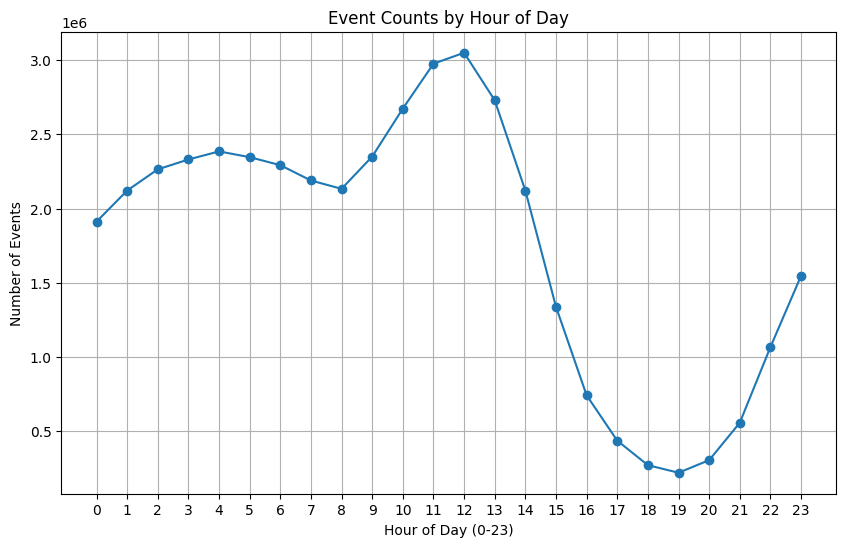

Wall time: 0.857 s
RSS Δ: +36.89 MB
Peak memory Δ: +19.58 MB (OS-dependent)


<ExecutionResult object at 10d9f9b50, execution_count=None error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 10da16270, raw_cell="# codecell_36c (keep this id for tracking purposes.." store_history=False silent=False shell_futures=True cell_id=None> result=None>

In [20]:
%%timemem
# codecell_36c (keep this id for tracking purposes)

import matplotlib.pyplot as plt

events_by_hour_pdf = events_by_hour_df.toPandas()

# TODO: Write your code below, but do not remove any lines already in this cell.
plt.figure(figsize=(10,6))
plt.plot(events_by_hour_pdf['hour'], events_by_hour_pdf['count'], marker='o', linestyle='-')
plt.title('Event Counts by Hour of Day')
plt.xlabel('Hour of Day (0-23)')
plt.ylabel('Number of Events')
plt.xticks(range(0,24))
plt.grid(True)


plt.show()

### 3.7 Q7

We are going to analyze the "big" brands. Find out the average purchase price by brand, and restrict to cases where the average is more than 10K.
We want the results sorted by the average purchase price from the largest to smallest value.
(Report answers to two digits after the decimal point, i.e., XX.XX, but it's okay if the output only contains one digit after the decimal point.)

First, do it using SQL:

In [21]:
%%timemem
# codecell_37a (keep this id for tracking purposes)

#assuming more than 10k refers to the average price 
# Write your SQL below
sql_query = f"""
SELECT 
  b.brand_code,
  ROUND(AVG(e.price), 2) AS avg_price
FROM events e
JOIN brands b ON e.brand_key = b.brand_key
WHERE e.event_type = 'purchase'
GROUP BY b.brand_code
HAVING AVG(e.price) > 10000
ORDER BY avg_price DESC
"""

results = spark.sql(sql_query)

results.show()

+----------+---------+
|brand_code|avg_price|
+----------+---------+
|      adam|  58946.0|
|      kona|  43759.0|
|  yuandong|  35329.0|
|   bentley|  23164.0|
|      otex| 18633.14|
|    suunto| 10732.82|
|     stark| 10400.25|
+----------+---------+

Wall time: 0.709 s
RSS Δ: +0.03 MB
Peak memory Δ: +0.00 MB (OS-dependent)


<ExecutionResult object at 11156f590, execution_count=None error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 10d957f50, raw_cell="# codecell_37a (keep this id for tracking purposes.." store_history=False silent=False shell_futures=True cell_id=None> result=None>

Next, do it with DataFrames:

In [22]:
%%timemem
# codecell_37b (keep this id for tracking purposes)

# TODO: Write your code below, but do not remove any lines already in this cell.
purchase_events = events_df.filter(col("event_type") == "purchase")
joined_df = purchase_events.join(brands_df, "brand_key")
avg_price_by_brand_df = joined_df.groupBy("brand_code") \
    .agg(round(avg("price"), 2).alias("avg_price")) \
    .filter(col("avg_price") > 10000) \
    .orderBy(col("avg_price").desc())


avg_price_by_brand_df.show()

+----------+---------+
|brand_code|avg_price|
+----------+---------+
|      adam|  58946.0|
|      kona|  43759.0|
|  yuandong|  35329.0|
|   bentley|  23164.0|
|      otex| 18633.14|
|    suunto| 10732.82|
|     stark| 10400.25|
+----------+---------+

Wall time: 0.353 s
RSS Δ: +0.00 MB
Peak memory Δ: +0.00 MB (OS-dependent)


<ExecutionResult object at 10d9f8410, execution_count=None error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 10da17000, raw_cell="# codecell_37b (keep this id for tracking purposes.." store_history=False silent=False shell_futures=True cell_id=None> result=None>

When you run the cell above, `avg_price_by_brand_df` should be something like:

```
+----------+------------------+
|brand_code|         avg_price|
+----------+------------------+
|       ???|               ???|
        ...
|       ???|               ???|
+----------+------------------+
```

Now plot the above DataFrame using `matplotlib`.
Here we want a bar chart, with each of the brands as a bar, and the average price on the _y_ axis.

**Hint:** use the code below to get started.

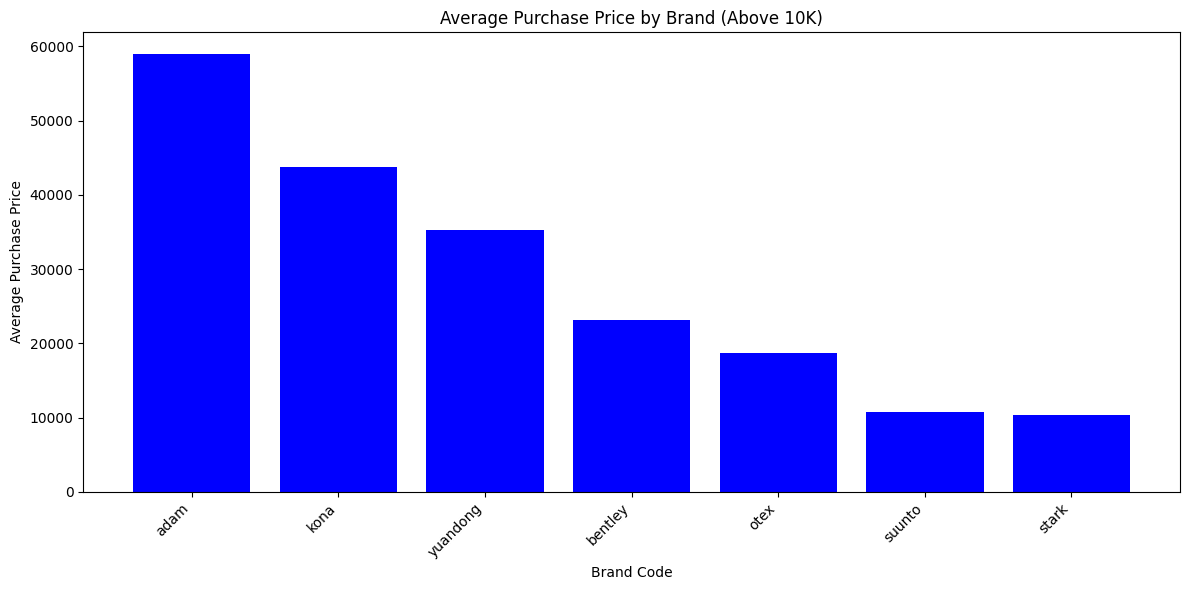

Wall time: 0.420 s
RSS Δ: +9.05 MB
Peak memory Δ: +8.14 MB (OS-dependent)


<ExecutionResult object at 111597350, execution_count=None error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 111618130, raw_cell="# codecell_37c (keep this id for tracking purposes.." store_history=False silent=False shell_futures=True cell_id=None> result=None>

In [23]:
%%timemem
# codecell_37c (keep this id for tracking purposes)

import matplotlib.pyplot as plt

avg_price_by_brand_pdf = avg_price_by_brand_df.toPandas()

# TODO: Write your code below, but do not remove any lines already in this cell.
plt.figure(figsize=(12, 6))
plt.bar(avg_price_by_brand_pdf['brand_code'], avg_price_by_brand_pdf['avg_price'], color='blue')
plt.title('Average Purchase Price by Brand (Above 10K)')
plt.xlabel('Brand Code')
plt.ylabel('Average Purchase Price')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

## 4. Load RDDs

The remaining exercises focus on RDD manipulations.

Let's start by loading the RDDs.

In [24]:
# Get RDDs directly from DataFrames (with required repartitions)
# type: RDD[Row]
events_rdd   = events_df.rdd.repartition(1000)
products_rdd = products_df.rdd.repartition(100)
brands_rdd   = brands_df.rdd.repartition(100)

You'll need `Row`, so let's make sure we've imported it.

In [25]:
from pyspark.sql import Row

## 5. Implementations of Computing Averages

In this next exercise, we're going to implement "computing the mean", as decribed <a href="https://lintool.github.io/cs451-2025f/slides/cs451-2025f-week03b-slides-v1.01.pdf#page=30">here</a> (version 1) and <a href="https://lintool.github.io/cs451-2025f/slides/cs451-2025f-week03b-slides-v1.01.pdf#page=32">here</a> (version 3) in Spark.

To make the problem more tractable (i.e., to reduce the running times), let's first do a bit of filtering of the `events` table.
We'll do this using DataFrames, and then generate an RDD:

In [26]:
filtered_events_df = (
    events_df
        .filter((F.col("event_type") == "purchase") & F.col("price").isNotNull())
        .join(brands_df, on="brand_key")
)

filtered_events_df.count()

print(f"Number of rows in events          table: {events_df.count()}")
print(f"Number of rows in filtered events table: {filtered_events_df.count()}")

filtered_events_rdd = filtered_events_df.rdd


# Restore the built-in round
round = __builtins__.round
print(round)


Number of rows in events          table: 42351862
Number of rows in filtered events table: 664885
<built-in function round>


You can confirm that we're working with a smaller dataset.

Compute the average purchase price by brand. We want the results sorted by the average purchase price from the largest to smallest value. As before, round to two digits after the decimal point. This is similar to Q7 above, except _without_ the "more than 10K" condition.

Implement using the naive **"version 1"** algorithm, as described in the lectures:

+ You _must_ start with `filtered_events_rdd`.
+ You _must_ use `groupByKey()`.
+ Per "version 1", your implementation _must_ shuffle all values from the "mappers" to the "reducers".

<font color="red">**Below, you'll have to write some code!**</font>

In [27]:
%%timemem
# codecell_5x1 (keep this id for tracking purposes)

# TODO: Write your code below, but do not remove any lines already in this cell.


brand_price_rdd = filtered_events_rdd.map(lambda row: (row.brand_key, row.price))

grouped_rdd = brand_price_rdd.groupByKey()

def compute_average(prices):
    total = 0
    count = 0
    for price in prices:
        total += price
        count += 1
    return round(total / count, 2) if count > 0 else 0

average_rdd = grouped_rdd.mapValues(compute_average)

average_revenue_per_brand_v1 = average_rdd.sortBy(lambda kv: kv[1], ascending=False)

average_revenue_per_brand_v1.take(10)

[(26, 58946.0),
 (1667, 43759.0),
 (3392, 35329.0),
 (367, 23164.0),
 (2346, 18633.13),
 (2962, 10732.82),
 (2894, 10400.25),
 (3416, 9447.0),
 (304, 8504.19),
 (509, 8288.42)]

Wall time: 132.637 s
RSS Δ: -39.45 MB
Peak memory Δ: +0.47 MB (OS-dependent)


<ExecutionResult object at 11165ec90, execution_count=None error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 11161b9a0, raw_cell="# codecell_5x1 (keep this id for tracking purposes.." store_history=False silent=False shell_futures=True cell_id=None> result=[(26, 58946.0), (1667, 43759.0), (3392, 35329.0), (367, 23164.0), (2346, 18633.13), (2962, 10732.82), (2894, 10400.25), (3416, 9447.0), (304, 8504.19), (509, 8288.42)]>

Compute the average purchase price by brand. We want the results sorted by the average purchase price from the largest to smallest value. As before, round to two digits after the decimal point. This is similar to Q7 above, except _without_ the "more than 10K" condition.

Implement using the improved **"version 3"** algorithm, as described in the lectures:

+ You _must_ start with `filtered_events_rdd`.
+ You _must_ use `reduceByKey()`.
+ Per "version 3", your implementation _must_ emit `(sum, count)` pairs and take advantage opportunities to perform aggregations.

<font color="red">**Below, you'll have to write some code!**</font>

In [28]:
%%timemem
# codecell_5x2 (keep this id for tracking purposes)

# TODO: Write your code below, but do not remove any lines already in this cell.
brand_price_count_rdd = filtered_events_rdd.map(lambda row: (row.brand_key, (row.price, 1)))

#tuple (price, count) accumulated to accumulator one by one to the respective brand key
sum_count_rdd = brand_price_count_rdd.reduceByKey(
    lambda acc, val: (acc[0] + val[0], acc[1] + val[1])
)

#compute the average from tuple of (total_price, count) by dividng, repeat for each key
average_rdd = sum_count_rdd.mapValues(
    lambda sum_count: round(sum_count[0] / sum_count[1], 2)
)

average_revenue_per_brand_v3 = average_rdd.sortBy(lambda kv: kv[1], ascending=False)

average_revenue_per_brand_v3.take(10)

[(26, 58946.0),
 (1667, 43759.0),
 (3392, 35329.0),
 (367, 23164.0),
 (2346, 18633.13),
 (2962, 10732.82),
 (2894, 10400.25),
 (3416, 9447.0),
 (304, 8504.19),
 (509, 8288.42)]

Wall time: 133.384 s
RSS Δ: +0.95 MB
Peak memory Δ: +0.00 MB (OS-dependent)


<ExecutionResult object at 1116ff6b0, execution_count=None error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 1116fb3f0, raw_cell="# codecell_5x2 (keep this id for tracking purposes.." store_history=False silent=False shell_futures=True cell_id=None> result=[(26, 58946.0), (1667, 43759.0), (3392, 35329.0), (367, 23164.0), (2346, 18633.13), (2962, 10732.82), (2894, 10400.25), (3416, 9447.0), (304, 8504.19), (509, 8288.42)]>

## 6. Implementations of Joins

Next, we're going to implement joins.

Our join implementations will be general, but we're going to check correctness using the following query:

In [29]:
spark.sql("""

SELECT * FROM brands b
JOIN products p ON p.brand_key = b.brand_key
WHERE b.brand_key = '423'

""").show()

+----------+--------------------+---------+-------------+----------+----------+------------+--------------------+---------+------------+-----------+
|brand_code|          brand_desc|brand_key|category_code|brand_code|product_id|product_name|        product_desc|brand_key|category_key|product_key|
+----------+--------------------+---------+-------------+----------+----------+------------+--------------------+---------+------------+-----------+
| blaupunkt|"Blaupunkt is a G...|      423|  electronics| blaupunkt|   1802099|    video.tv|The video.tv is a...|      423|           8|       4813|
| blaupunkt|"Blaupunkt is a G...|      423|  electronics| blaupunkt|   1802107|    video.tv|The video.tv is a...|      423|           8|       4821|
+----------+--------------------+---------+-------------+----------+----------+------------+--------------------+---------+------------+-----------+



### 6.1 Shuffle Join Implementation

Here, we're going to implement a shuffle join, aka reduce-side join.

Write the function `shuffle_join`, as follows:
+ Takes in `R`, `S`, `keyR`, and `keyS`: `R` and `S` are the RDDs to be joined; `keyR` and `keyS` are the join keys in `R` and `S`, respectively (type string).
+ The output is an RDD of `Row`s that corresponds to the inner join on the keys.

The function should implement a shuffle join between the two RDDs (as discussed in lecture).
Specifically:
+ You _cannot_ use the `join` (or any related) transformation on RDDs, because that would defeat the point of the exercise.
+ If you have any additional questions about allowed or disallowed transformations, ask!

Note that in SQL, `keyR` and `keyS` are repeated in the joined output (i.e., you get duplicate columns).
Here, you just want one copy.
Hint: Concatenate the `Row`s but keep only one copy of the join key.

<font color="red">**Below, you'll have to write some code!**</font>

In [30]:
# codecell_61a (keep this id for tracking purposes)

#def shuffle_join(R, S, keyR, keyS):

#from pyspark.sql import Row

def shuffle_join(R, S, keyR, keyS):
    #tuple (key, (tag, row_itself))
    r_kv = R.map(lambda row: (row[keyR], ('R', row)))
    s_kv = S.map(lambda row: (row[keyS], ('S', row)))
    
    #combine into one big union
    combined = r_kv.union(s_kv)
    
    #group the big union by keys (id=1 group..)
    grouped = combined.groupByKey()
    
    #make joined row function
    def join_rows(key, rows):
        r_rows = []
        s_rows = []
        #for each group(id=1..) separate it out to R group and S group
        for tag, row in rows:
            if tag == 'R':
                r_rows.append(row)
            else:
                s_rows.append(row)
        
        joined = []
        #merge each row from R with each row from S  
        for r in r_rows:
            for s in s_rows:
                #Convert them to dictionary to get proper key value pairs
                merged = r.asDict()
                for k, v in s.asDict().items():
                    #skip merging the key field
                    if k != keyS:
                        #add key and value to row being created 
                        #note that this also essentially removes duplicate collumns with the same name 
                        merged[k] = v
                #python expand dictionary to row with ** and append it to joined rows
                joined.append(Row(**merged))
        return joined

    #create merged row from each group and merge them to one using flatmap
    joined_rdd = grouped.flatMap(lambda kv: join_rows(kv[0], kv[1]))

    return joined_rdd





Let's try to use it!

In [31]:
%%timemem

shuffle_join_rdd = shuffle_join(brands_rdd, products_rdd, "brand_key", "brand_key")
shuffle_join_rdd.count()

115584

Wall time: 3.550 s
RSS Δ: -47.11 MB
Peak memory Δ: +0.00 MB (OS-dependent)


<ExecutionResult object at 1116ff470, execution_count=None error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 11161ba10, raw_cell="
shuffle_join_rdd = shuffle_join(brands_rdd, produ.." store_history=False silent=False shell_futures=True cell_id=None> result=115584>

Add in the `WHERE` clause:

In [32]:
shuffle_join_results_rdd = shuffle_join_rdd.filter(lambda row: row["brand_key"] == 423)
shuffle_join_results_rdd.count()

2

If you look at the results, they're a bit difficult to read... why don't we just use Spark DataFrames for prettification?

In [33]:
df = spark.createDataFrame(shuffle_join_results_rdd.collect())
df.show()

+----------+--------------------+---------+-------------+----------+------------+--------------------+------------+-----------+
|brand_code|          brand_desc|brand_key|category_code|product_id|product_name|        product_desc|category_key|product_key|
+----------+--------------------+---------+-------------+----------+------------+--------------------+------------+-----------+
| blaupunkt|"Blaupunkt is a G...|      423|  electronics|   1802099|    video.tv|The video.tv is a...|           8|       4813|
| blaupunkt|"Blaupunkt is a G...|      423|  electronics|   1802107|    video.tv|The video.tv is a...|           8|       4821|
+----------+--------------------+---------+-------------+----------+------------+--------------------+------------+-----------+



Verify output against the SQL query.

### 6.2 Replicated Hash Join Implementation

Here, we're going to implement a replicated hash join.

Write the function `replicated_hash_join`, as follows:
+ Takes in `R`, `S`, `keyR`, and `keyS`: `R` and `S` are the RDDs to be joined; `keyR` and `keyS` are the join keys in `R` and `S`, respectively (type string).
+ The output is an RDD of `Row`s that corresponds to the inner join on the keys.

The function should implement a hash join between the two RDDs (as discussed in lecture).
Specifically:
+ `R` is the dataset you load into memory and replicate.
+ You _cannot_ use the `join` (or any related) transformation on RDDs, because that would defeat the point of the exercise.
+ If you have any additional questions about allowed or disallowed transformations, ask!

Note that in SQL, `keyR` and `keyS` are repeated in the joined output (i.e., you get duplicate columns).
Here, you just want one copy.
Hint: Concatenate the `Row`s but keep only one copy of the join key.

<font color="red">**Below, you'll have to write some code!**</font>

In [34]:
# codecell_62a (keep this id for tracking purposes)

#def replicated_hash_join(R, S, keyR, keyS):

def replicated_hash_join(R, S, keyR, keyS):
    r_data = R.collect()
    
    #make a lookup table for each key 
    r_lookup = {}
    for row in r_data:
        join_key = row[keyR]
        r_lookup.setdefault(join_key, []).append(row)
    
    #just send over the entire lookup table to everyone
    broadcast_r = sc.broadcast(r_lookup)
    
    #join S with the lookup table
    def join_with_broadcast(s_row):
        s_key = s_row[keyS]
        #find matching rows in the broadcasted lookup table
        matches = broadcast_r.value.get(s_key, [])
        joined_rows = []
        for r_row in matches:
            #merge dictionaries the same way as shuffle join
            merged = r_row.asDict()
            for k, v in s_row.asDict().items():
                if k != keyS:
                    merged[k] = v
            joined_rows.append(Row(**merged))
        return joined_rows

    #repeat process of merging with the whole S 
    joined_rdd = S.flatMap(join_with_broadcast)

    return joined_rdd





Let's try to use it!

In [35]:
%%timemem

replicated_hash_join_rdd = replicated_hash_join(brands_rdd, products_rdd, "brand_key", "brand_key")
replicated_hash_join_rdd.count()

115584

Wall time: 0.327 s
RSS Δ: +10.59 MB
Peak memory Δ: +0.00 MB (OS-dependent)


<ExecutionResult object at 11175c350, execution_count=None error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 11174d6a0, raw_cell="
replicated_hash_join_rdd = replicated_hash_join(b.." store_history=False silent=False shell_futures=True cell_id=None> result=115584>

Add in the `WHERE` clause:

In [36]:
replicated_hash_join_results_rdd = replicated_hash_join_rdd.filter(lambda row: row["brand_key"] == 423)
replicated_hash_join_results_rdd.count()

2

If you look at the results, they're a bit difficult to read... why don't we just use Spark DataFrames for prettification?

In [37]:
df = spark.createDataFrame(replicated_hash_join_results_rdd.collect())
df.show()

+----------+--------------------+---------+-------------+----------+------------+--------------------+------------+-----------+
|brand_code|          brand_desc|brand_key|category_code|product_id|product_name|        product_desc|category_key|product_key|
+----------+--------------------+---------+-------------+----------+------------+--------------------+------------+-----------+
| blaupunkt|"Blaupunkt is a G...|      423|  electronics|   1802099|    video.tv|The video.tv is a...|           8|       4813|
| blaupunkt|"Blaupunkt is a G...|      423|  electronics|   1802107|    video.tv|The video.tv is a...|           8|       4821|
+----------+--------------------+---------+-------------+----------+------------+--------------------+------------+-----------+



Verify output against the SQL query.

## 7. Join Performance

Now that we have two different implementations of joins, let's compare them, on the _same exact query_.
The first two are repeated from above.

Let's call this J1 below.
(Run the cell, it should just work. If it doesn't you'll need to fix the implementation above.)

In [38]:
%%timemem

shuffle_join_rdd = shuffle_join(brands_rdd, products_rdd, "brand_key", "brand_key").filter(lambda row: row["brand_key"] == 423)
shuffle_join_rdd.count()

2

Wall time: 2.945 s
RSS Δ: +0.05 MB
Peak memory Δ: +0.00 MB (OS-dependent)


<ExecutionResult object at 11167f5f0, execution_count=None error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 111553a80, raw_cell="
shuffle_join_rdd = shuffle_join(brands_rdd, produ.." store_history=False silent=False shell_futures=True cell_id=None> result=2>

Let's call this J2 below.
(Run the cell, it should just work. If it doesn't you'll need to fix the implementation above.)

In [39]:
%%timemem

replicated_hash_join_rdd = replicated_hash_join(brands_rdd, products_rdd, "brand_key", "brand_key").filter(lambda row: row["brand_key"] == 423)
replicated_hash_join_rdd.count()

2

Wall time: 0.335 s
RSS Δ: +5.02 MB
Peak memory Δ: +0.00 MB (OS-dependent)


<ExecutionResult object at 11167f590, execution_count=None error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 111551a20, raw_cell="
replicated_hash_join_rdd = replicated_hash_join(b.." store_history=False silent=False shell_futures=True cell_id=None> result=2>

Let's call this J3 below.
(Run the cell, it should just work. If it doesn't you'll need to fix the implementation above.)

In [40]:
%%timemem

replicated_hash_join_rdd = replicated_hash_join(products_rdd, brands_rdd, "brand_key", "brand_key").filter(lambda row: row["brand_key"] == 423)
replicated_hash_join_rdd.count()

2

Wall time: 5.152 s
RSS Δ: -49.22 MB
Peak memory Δ: +250.80 MB (OS-dependent)


<ExecutionResult object at 1114cd010, execution_count=None error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 1114bbb60, raw_cell="
replicated_hash_join_rdd = replicated_hash_join(p.." store_history=False silent=False shell_futures=True cell_id=None> result=2>

J1, J2, and J3 should give you exactly the same results.
After all, they're just different implementations of the same query.

Answer the questions below.

In [41]:
print(products_rdd.count())
print(brands_rdd.count())

166794
3444


<font color="red">**Put your answers below! Replace X.X and the placeholders with your actual answers.**</font>

// qcell_7x1290 (keep this id for tracking purposes)

**What are the running times of J1, J2, and J3**?
(You might want to run the cells a few times and take the average.)

- **Running time of J1:** <font color="red">3.5</font> seconds
- **Running time of J2:** <font color="red">0.4</font> seconds
- **Running time of J3:** <font color="red">4.9</font> seconds

**Explain:**

+ If the running times are what you expect, explain why X > Y > Z.
+ If the running times are _not_ what you expect, explain what they _should_ be, and then explain why X > Y > Z.
+ Specifically compare J2 and J3.

<font color="red">Your answer goes here.</font> \
I would expect the merging of rows in hash join using a lookup table to be quicker than shuffling and grouping all the rows in shuffle join. That said J3 being the slowest is not a surprise as loading a large dataset to memory, hashing and distributing it is going to take more time. In this case even more than performing a shuffle join. Comparing J2 and J3, the merging part at the end is going to be the same either way as we have to loop through every row anyways. The time diffference comes from J2 creating and broadcasting a much smaller lookup table than J3, saving computation time and being more likely to fit everything into memory.

# 8. Submission

Details about the submission of this assignment are outlined in the <a href="https://lintool.github.io/cs451-2025f/assignments/assignment3.html">assignment 3 landing page</a>.

In [42]:
%%timemem
spark.stop()

Wall time: 0.999 s
RSS Δ: +1.11 MB
Peak memory Δ: +0.00 MB (OS-dependent)


<ExecutionResult object at 1114cf8f0, execution_count=None error_before_exec=None error_in_exec=None info=<ExecutionInfo object at 1116fbb60, raw_cell="spark.stop()
" store_history=False silent=False shell_futures=True cell_id=None> result=None>